# 1 · Which signal should tell a data scientist to retrain?

**The situation:** a model is in production. The world it learned from may change. A monitoring rule
watches something and, when it crosses a line, pages a data scientist to retrain. Retraining costs
time and compute; *not* retraining costs bad predictions. What should the rule watch?

**The test bench:** simulated data streams (think: one batch per week, 500 rows each) where we decide
exactly when and how the world changes, so we know the right answer:

| Scenario | What changes | Should we retrain? |
|---|---|---|
| none | nothing | no |
| covariate_harmless | the inputs move, but where the model already works | no |
| covariate_harmful | the inputs move where the model never learned | yes |
| concept_sudden | the *meaning* changes: same inputs, different right answer | yes |
| concept_gradual | the same, phased in over 20 batches | yes |
| concept_complex | the relationship becomes much more intricate | yes |

The change starts at batch 40 of 80. The model (gradient-boosted trees, tuned at the start) trains on
batches 0-19. True answers ("labels") come back 2 batches late, as they do in real life.

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retrain import plot
plot.style()
pd.set_option('display.width', 160)
LABELS = {'never': 'never retrain', 'schedule': 'every 10 batches', 'psi': 'input drift: PSI',
          'psi_rule': 'input drift: PSI > 0.2 rule', 'ks': 'input drift: KS test', 'c2st': 'input drift: classifier test',
          'pred_psi': 'prediction drift: PSI', 'error': 'error ratio', 'page_hinkley': 'Page-Hinkley (error)',
          'psi_error': 'input flag + error confirms', 'error_cp': 'error ratio + change point',
          'page_hinkley_cp': 'Page-Hinkley + change point', 'oracle': 'oracle (knows the change)'}

from retrain import simulate, detectors
d = pd.read_csv('results/synthetic_runs.csv')
t = d[d.study == 'triggers']

## 1 · What the drift looks like

For three scenarios, the first input feature and the target, before (grey) and after (colour) the change.
In *concept_sudden* the inputs look identical: only the relationship between input and target moved.

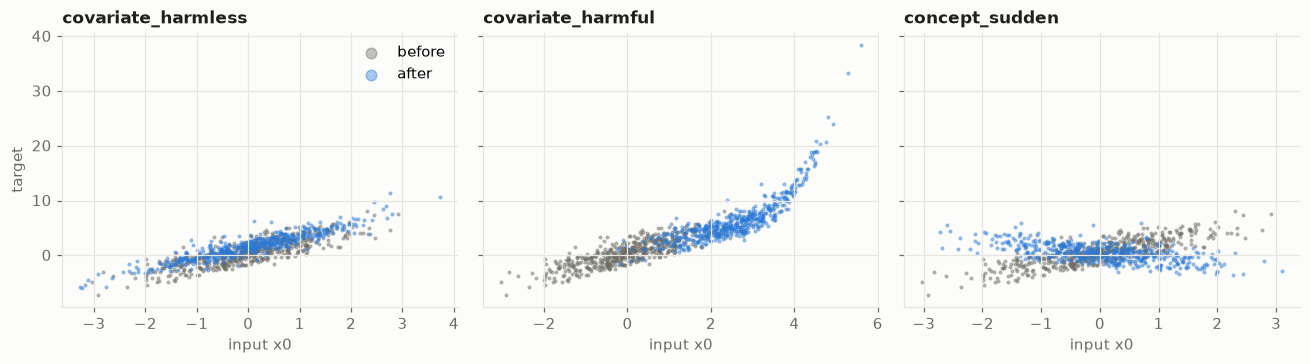

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, sc in zip(axes, ['covariate_harmless', 'covariate_harmful', 'concept_sudden']):
    s = simulate.stream(sc, 0)
    for b, col in ((30, plot.MUTED), (55, plot.SERIES[0])):
        ax.scatter(s.X[b][:, 0], s.y[b], s=3, alpha=0.4, color=col, label='before' if b < 40 else 'after')
    ax.set_title(sc); ax.set_xlabel('input x0')
axes[0].set_ylabel('target'); axes[0].legend(markerscale=4)
plt.tight_layout()

## 2 · A fair comparison: same false-alarm rate for every trigger

A more sensitive trigger catches more and also cries wolf more. So every trigger's threshold is set so
that on *drift-free* streams (50 calibration streams, never reused for testing) it fires in about 1 batch
in 300. The common industry rule "PSI above 0.2" is kept as an extra, uncalibrated row.

In [3]:
pd.Series(json.load(open('results/thresholds.json'))['thresholds']).round(3).rename('calibrated threshold')

psi             0.058
ks              2.435
c2st            0.559
pred_psi        0.053
error           1.089
page_hinkley    0.374
psi_error       1.045
Name: calibrated threshold, dtype: float64

## 3 · The result: 30 streams per scenario

**Total cost** = summed prediction error over the 60 production batches (retrains not yet priced in).
Lower is better. ± = 95% interval over the 30 streams.

In [4]:
def ci(x):
    rng = np.random.default_rng(0); b = rng.choice(x.values, (2000, len(x))).mean(1)
    return (np.percentile(b, 97.5) - np.percentile(b, 2.5)) / 2
order = ['never', 'schedule', 'psi_rule', 'psi', 'ks', 'c2st', 'pred_psi', 'psi_error', 'error', 'page_hinkley',
         'error_cp', 'page_hinkley_cp', 'oracle']
g = t.groupby(['trigger', 'scenario']).error_total
tab = (g.mean().round(1).astype(str) + ' ± ' + g.apply(ci).round(1).astype(str)).unstack().reindex(order)
tab.index = [LABELS[i] for i in tab.index]
tab[list(simulate.SCENARIOS)]

scenario,none,covariate_harmless,covariate_harmful,concept_sudden,concept_gradual,concept_complex
never retrain,25.3 ± 0.1,25.3 ± 0.1,73.1 ± 1.2,105.4 ± 0.3,82.0 ± 0.2,86.6 ± 0.2
every 10 batches,26.0 ± 0.1,25.9 ± 0.1,42.9 ± 0.5,48.9 ± 0.2,46.9 ± 0.1,59.1 ± 2.4
input drift: PSI > 0.2 rule,25.3 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,105.4 ± 0.3,82.0 ± 0.2,86.6 ± 0.2
input drift: PSI,25.3 ± 0.1,25.7 ± 0.1,37.7 ± 0.5,100.6 ± 4.3,79.1 ± 2.6,84.4 ± 2.4
input drift: KS test,25.4 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,96.7 ± 6.4,77.8 ± 3.1,82.2 ± 3.3
input drift: classifier test,25.4 ± 0.1,25.7 ± 0.1,37.9 ± 0.6,102.0 ± 3.5,80.2 ± 2.0,84.5 ± 2.2
prediction drift: PSI,25.3 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,100.9 ± 4.6,80.3 ± 1.7,84.7 ± 2.0
input flag + error confirms,25.3 ± 0.1,25.6 ± 0.1,39.8 ± 0.6,100.6 ± 4.3,79.1 ± 2.6,84.4 ± 2.4
error ratio,25.3 ± 0.1,25.3 ± 0.1,40.6 ± 1.1,62.9 ± 2.4,45.0 ± 0.4,65.1 ± 2.3
Page-Hinkley (error),25.3 ± 0.1,25.3 ± 0.1,39.6 ± 0.6,47.0 ± 0.2,42.7 ± 0.3,61.6 ± 3.1


In [5]:
harm = ['covariate_harmful', 'concept_sudden', 'concept_gradual', 'concept_complex']
h = t[t.scenario.isin(harm)]
summary = pd.DataFrame({
    'concept drift caught (share of streams)': h[h.scenario.str.startswith('concept')].assign(c=lambda x: x.first_retrain_delay.notna() & (x.first_retrain_delay < 15)).groupby('trigger').c.mean(),
    'median batches to first retrain': h.groupby('trigger').first_retrain_delay.median(),
    'wasted retrains per harmless stream': t[t.scenario == 'covariate_harmless'].groupby('trigger').wasted_retrains.mean(),
}).reindex(order).round(2)
summary.index = [LABELS[i] for i in summary.index]
summary

,concept drift caught (share of streams),median batches to first retrain,wasted retrains per harmless stream
never retrain,0.00,NaN,0.00
every 10 batches,1.00,0.0,5.00
input drift: PSI > 0.2 rule,0.00,0.0,3.00
input drift: PSI,0.07,0.0,3.20
input drift: KS test,0.10,0.0,3.07
input drift: classifier test,0.07,0.0,3.10
prediction drift: PSI,0.10,0.0,3.17
input flag + error confirms,0.07,2.0,0.80
error ratio,1.00,2.0,0.10
Page-Hinkley (error),1.00,2.0,0.07


**Reading it:**

- **Input-drift triggers are blind to concept drift.** PSI, KS, the classifier test and prediction
  drift fire on the meaning-changes only at their false-alarm rate (the occasional "catch" 15+ batches
  later is luck). The PSI > 0.2 rule never fires at all.
- **They pay for harmless drift:** about 3 retrains per stream when the inputs moved somewhere the
  model already handled.
- **Error-based triggers catch every harmful change** within 2-5 batches, and almost never retrain for
  nothing. Their catch: they need labels.
- **Where input drift wins:** when inputs move into new territory, it fires instantly (before any labels
  arrive), and is slightly cheaper there (37.7 vs 40.6).

## 4 · Detecting fast isn't enough: retrain on the right data

The plain error trigger notices sudden concept drift within 2 batches, yet costs far more than the
oracle (62.9 vs 38.9). It retrains on the last 10 batches, which are mostly *from before the change*,
so the new model is a blend of the old world and the new one.

**Change-point window:** Page-Hinkley's running sum of excess error has its lowest point just before
the change began. Retraining only on data after that point (and waiting until there is enough of it)
nearly closes the gap: 43.0, with half the retrains. It hurts when inputs move to new territory (47.0
vs 40.6), where the post-change window is too small.

## 5 · Pricing the retrain: which trigger is cheapest?

Each retrain costs a data scientist's time and compute. Expressed in "batches of normal prediction
error", the cheapest trigger on average across all six scenarios:

,0,1,2,5,10,20,40
cheapest trigger,Page-Hinkley + change point,Page-Hinkley + change point,Page-Hinkley + change point,error ratio + change point,error ratio + change point,never retrain,never retrain


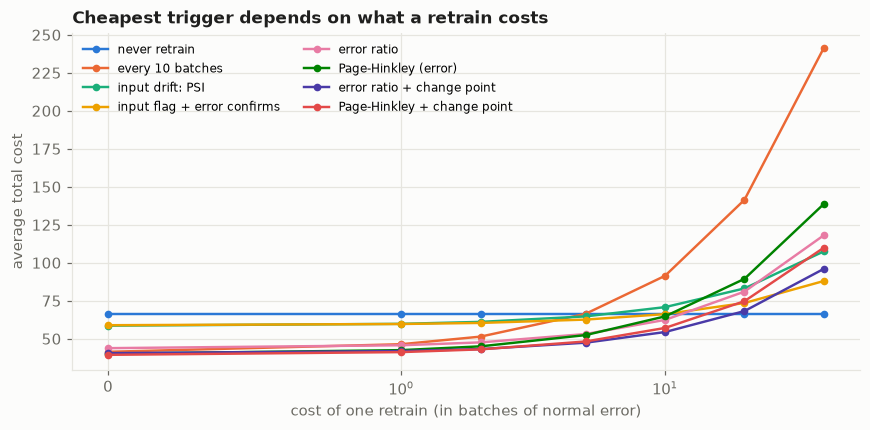

In [6]:
cc = pd.read_csv('results/cost_curve_synthetic.csv', index_col=0)
cc.columns = cc.columns.astype(int)
show = ['never', 'schedule', 'psi', 'psi_error', 'error', 'page_hinkley', 'error_cp', 'page_hinkley_cp']
fig, ax = plt.subplots(figsize=(8, 4))
for k, name in enumerate(show):
    ax.plot(cc.columns, cc.loc[name], marker='o', markersize=4, color=plot.SERIES[k % 8], label=LABELS[name])
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('cost of one retrain (in batches of normal error)')
ax.set_ylabel('average total cost'); ax.set_title('Cheapest trigger depends on what a retrain costs')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
best = cc.drop(index='oracle').idxmin().map(LABELS)
best.rename('cheapest trigger').to_frame().T

- **Cheap retrains (0-2):** Page-Hinkley with a change-point window.
- **Moderate (5-10):** error ratio with a change-point window: it retrains less often.
- **Very expensive (20+):** in this simulation, never retraining wins: no change is costly enough
  to pay for the data scientist. In a real business that threshold is a number worth knowing.
- **Input-drift triggers are never the cheapest**, at any price.

**What this means in practice:** page on *performance* when labels come back reasonably fast; use input
drift as an early, low-priority flag (and as the only signal when labels never come back); and when you
retrain, train on data from after the change, not a fixed window.